# NewsScope - 04. Text Clustering

## Phase E: Unsupervised Text Mining and Document Clustering

This notebook implements and evaluates unsupervised text clustering on the **AG News** dataset. The objective is to discover natural topical groupings without using supervisory category labels during feature extraction or cluster assignment.

### Planned Experiments
- **Document Representations**: TF-IDF (sparse n-gram term weighting) and Word2Vec (dense continuous semantic embeddings).
- **Clustering Algorithms**: K-Means (centroid-based partitioning) and Agglomerative Hierarchical Clustering.
- **Distance Metrics**: Euclidean distance and Cosine distance.
- **Intrinsic Evaluation**: Silhouette Score and Davies-Bouldin Index.
- **Cluster Visualisation**: 2D projection and contingency analysis against ground-truth categories.

## Stage A: Setup & Stratified Sampling

In this stage, we configure the environment, establish output directories, and load the preprocessed training dataset (`train_processed.csv`). 

### Sampling Strategy
Hierarchical clustering computes an $N \times N$ pairwise distance matrix ($\mathcal{O}(N^2)$ space complexity). Evaluating all 120,000 articles would require over 115 GB of memory. To ensure computational tractability while preserving statistical representation, we draw a balanced, stratified sample of **3,000 documents** (750 articles per category) using `random_state=42`.

Category labels are strictly separated from the document text to maintain unsupervised integrity.

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Configure plot aesthetics
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# Resolve project paths relative to repository root
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
processed_dir = project_root / "data" / "processed"
results_dir = project_root / "results" / "clustering"
results_dir.mkdir(parents=True, exist_ok=True)

train_csv_path = processed_dir / "train_processed.csv"
assert train_csv_path.exists(), f"Processed dataset not found at: {train_csv_path}"

print("Libraries imported successfully.")
print(f"  Scikit-Learn: {sklearn.__version__}")
print(f"  Pandas:       {pd.__version__}")
print(f"  NumPy:        {np.__version__}")
print(f"  Output dir:   {results_dir}")

Libraries imported successfully.
  Scikit-Learn: 1.9.1
  Pandas:       3.1.1
  NumPy:        2.5.4
  Output dir:   c:\Users\Acer\Downloads\NewsScope\results\clustering


### Load Preprocessed Dataset & Draw Stratified Sample

We load `train_processed.csv`, sample 750 documents per category, and separate the input text (`clean_text`) from the ground-truth labels.

In [2]:
# Load preprocessed training corpus
full_df = pd.read_csv(train_csv_path)
print(f"Full dataset loaded: {len(full_df):,} documents across {full_df['category'].nunique()} categories.")

# Draw a reproducible stratified sample: 750 per category (3,000 total)
sample_df = (
    full_df.groupby("category", group_keys=False)
    .sample(n=750, random_state=RANDOM_STATE)
    .sample(frac=1.0, random_state=RANDOM_STATE)  # Shuffle row order
    .reset_index(drop=True)
)

# Extract document texts for clustering (unsupervised input)
documents = sample_df["clean_text"].tolist()

# Isolate ground-truth labels for post-hoc evaluation only
true_labels = sample_df["label"].to_numpy()
true_categories = sample_df["category"].to_numpy()
target_names = ["World", "Sports", "Business", "Sci/Tech"]

# Data integrity and verification checks
print("\n=== Stage A Verification ===")
print(f"Sample size:               {len(documents):,} documents")
print(f"Null texts:                {sample_df['clean_text'].isna().sum()}")
print(f"Empty string texts:        {(sample_df['clean_text'].str.strip() == '').sum()}")
print("\nClass distribution in sample:")
display(sample_df["category"].value_counts().rename_axis("Category").reset_index(name="Count"))

print("\nSample records preview:")
display(sample_df[["category", "clean_text"]].head(4))

Full dataset loaded: 120,000 documents across 4 categories.

=== Stage A Verification ===
Sample size:               3,000 documents
Null texts:                0
Empty string texts:        0

Class distribution in sample:


,Category,Count
0,Sports,750
1,Sci/Tech,750
2,Business,750
3,World,750



Sample records preview:


,category,clean_text
0,Sports,flintoff aim sign style london rounder andrew ...
1,Sci/Tech,rough patch xp update microsoft security minde...
2,Sports,american duo win opening beach volleyball matc...
3,Business,disney earnings rise million walt disney co sa...


## Stage B: Feature Representation & Normalisation

In this stage, we construct two contrasting document representations:
1. **TF-IDF (Term Frequency-Inverse Document Frequency)**: A high-dimensional, sparse lexical representation capturing term importance while discounting corpus-wide common words.
2. **Word2Vec Document Embeddings**: A low-dimensional, dense continuous representation capturing semantic similarities, constructed by mean-pooling Skip-gram word vectors across each article's tokens.

### Unsupervised Constraint
All vectorizers and embedding models are fitted strictly using the unlabelled `documents` text. Category labels (`true_labels`, `true_categories`) are completely excluded.

### The Role of $L_2$ Normalisation
In text clustering, documents vary considerably in length. Unnormalised vectors cause distance metrics (especially Euclidean distance) to cluster documents based on verbosity rather than topical content. 
Applying $L_2$ normalisation projects all document vectors onto a unit hypersphere ($\|\mathbf{x}\|_2 = 1$). Under unit length, squared Euclidean distance is directly proportional to cosine distance:
$$\|\mathbf{u} - \mathbf{v}\|_2^2 = \|\mathbf{u}\|_2^2 + \|\mathbf{v}\|_2^2 - 2(\mathbf{u} \cdot \mathbf{v}) = 2(1 - \cos(\mathbf{u}, \mathbf{v})) = 2 \times \text{Cosine Distance}$$
This enables distance-metric comparisons and allows standard Euclidean K-Means to function as Spherical K-Means.

### 1. TF-IDF Representation
We fit `TfidfVectorizer` on the sampled documents (`min_df=2` to eliminate singleton noise).

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Fit TF-IDF on sampled documents only
t0 = time.time()
tfidf_vectorizer = TfidfVectorizer(min_df=2, norm="l2")
X_tfidf = tfidf_vectorizer.fit_transform(documents)
tfidf_duration = time.time() - t0

# Compute sparsity metrics
n_samples, n_features = X_tfidf.shape
n_nonzero = X_tfidf.nnz
sparsity = 100.0 * (1.0 - (n_nonzero / (n_samples * n_features)))
zero_rows_tfidf = np.sum(X_tfidf.getnnz(axis=1) == 0)

print("=== TF-IDF Representation Summary ===")
print(f"Matrix shape:          {n_samples:,} documents × {n_features:,} features")
print(f"Data type:             {X_tfidf.dtype} (sparse CSR matrix)")
print(f"Non-zero elements:     {n_nonzero:,}")
print(f"Matrix sparsity:       {sparsity:.2f}%")
print(f"All-zero rows:         {zero_rows_tfidf}")
print(f"Extraction runtime:    {tfidf_duration:.2f}s")

# Sample prominent vocabulary terms
sample_terms = list(tfidf_vectorizer.vocabulary_.keys())[:8]
print(f"Sample vocabulary terms: {sample_terms}")

=== TF-IDF Representation Summary ===
Matrix shape:          3,000 documents × 5,976 features
Data type:             float64 (sparse CSR matrix)
Non-zero elements:     59,120
Matrix sparsity:       99.67%
All-zero rows:         0
Extraction runtime:    0.19s
Sample vocabulary terms: ['aim', 'sign', 'style', 'london', 'andrew', 'seek', 'cap', 'perfect']


### 2. Word2Vec Dense Embeddings
Following the architecture used in Phase D, we train a 100-dimensional Skip-gram Word2Vec model on the sampled document tokens:
- `vector_size=100`: 100-dimensional continuous vector space.
- `window=5`: Context window of 5 words to each side.
- `min_count=3`: Excludes words appearing fewer than 3 times in the sample.
- `sg=1`: Skip-gram architecture to capture fine-grained semantic associations.
- `workers=1`: Single-worker execution to ensure exact bit-for-bit reproducibility.
- `epochs=15`: 15 iterations over the sample.
- `seed=RANDOM_STATE`: Fixed seed for reproducible embedding weights.

Document vectors are formed by mean-pooling the word vectors for all recognized tokens in each article.

In [4]:
from gensim.models import Word2Vec
from sklearn.preprocessing import normalize

# Tokenize documents into word lists
tokenized_docs = [doc.split() for doc in documents]

# Train reproducible Word2Vec Skip-gram model
t0 = time.time()
w2v_model = Word2Vec(
    sentences=tokenized_docs,
    vector_size=100,
    window=5,
    min_count=3,
    sg=1,
    workers=1,
    epochs=15,
    seed=RANDOM_STATE,
)
w2v_duration = time.time() - t0

wv = w2v_model.wv
vec_size = w2v_model.vector_size

# Average word vectors to produce document vectors
def calculate_document_vector(tokens):
    vectors = [wv[w] for w in tokens if w in wv]
    if len(vectors) == 0:
        return np.zeros(vec_size, dtype=np.float32)
    return np.mean(vectors, axis=0)

X_w2v = np.array([calculate_document_vector(doc) for doc in tokenized_docs], dtype=np.float32)

# Create L2-normalised variant for cosine distance clustering
X_w2v_norm = normalize(X_w2v, norm="l2")

# Check for zero / unmapped document vectors
zero_rows_w2v = np.sum(np.all(X_w2v == 0, axis=1))

print("=== Word2Vec Representation Summary ===")
print(f"Vocabulary size:       {len(wv):,} unique words")
print(f"Dense matrix shape:    {X_w2v.shape[0]:,} documents × {X_w2v.shape[1]} dimensions")
print(f"Data type:             {X_w2v.dtype} (dense float32)")
print(f"All-zero rows:         {zero_rows_w2v}")
print(f"Training runtime:      {w2v_duration:.2f}s")
print(f"L2-normalised shape:   {X_w2v_norm.shape}")

# Inspect semantic neighbours for verification
for test_word in ["oil", "game", "microsoft"]:
    if test_word in wv:
        neighbors = [w for w, _ in wv.most_similar(test_word, topn=4)]
        print(f"  Similar to '{test_word}': {neighbors}")

=== Word2Vec Representation Summary ===
Vocabulary size:       4,682 unique words
Dense matrix shape:    3,000 documents × 100 dimensions
Data type:             float32 (dense float32)
All-zero rows:         0
Training runtime:      6.88s
L2-normalised shape:   (3000, 100)
  Similar to 'oil': ['crude', 'barrel', 'surprise', 'eased']
  Similar to 'game': ['super', 'detroit', 'hamstring', 'snapped']
  Similar to 'microsoft': ['xp', 'sp', 'window', 'mom']


## Stage C: Clustering Experiments

We systematically evaluate two clustering algorithms across two document representations and two distance metrics, keeping $k = 4$ clusters corresponding to the four underlying AG News categories:
1. **K-Means**: Centroid-based partitioning optimizing within-cluster sum of squares.
2. **Agglomerative Clustering**: Bottom-up hierarchical clustering recursively merging pairs of clusters.

### Algorithm & Distance Metric Compatibility
- **K-Means & Distance Handling**: Scikit-learn's `KMeans` strictly optimizes Euclidean distance. When applied to $L_2$-normalised vectors (`X_tfidf` and `X_w2v_norm`), it approximates direction-based cosine clustering because Euclidean distance on unit vectors is monotonically related to cosine distance:
  $$\|\mathbf{u} - \mathbf{v}\|_2^2 = 2(1 - \cos(\mathbf{u}, \mathbf{v}))$$
  We note this accurately as an **$L_2$-normalised Euclidean approximation of cosine clustering**, rather than true Spherical K-Means (because intermediate cluster centroids are arithmetic means that drift inside the unit hypersphere and are not re-projected to unit length at each iteration).
- **Agglomerative Clustering Linkage**: Ward's linkage (`linkage='ward'`) is mathematically defined only for Euclidean distance. For Cosine distance (`metric='cosine'`), we use average linkage (`linkage='average'`), which averages pairwise cosine distances between cluster members.
- **Methodological Consistency across Representations**:
  * **Euclidean Configurations**: Evaluated on unnormalised document vectors (`X_tfidf_unnorm` and `X_w2v`) across both K-Means and Agglomerative clustering, testing how algorithms behave when vector magnitude reflects document length variance.
  * **Cosine Configurations**: Evaluated on unit-normalised representations (`X_tfidf` and `X_w2v_norm`) across both algorithms, testing direction-based topical clustering.
- **Unsupervised Integrity**: Clustering algorithms receive only the document representations. Category labels (`true_labels`, `true_categories`) are strictly excluded.

### Execute the 8 Clustering Configurations

We train all 8 combinations on the shared 3,000-document sample, recording execution time and predicted cluster assignments.

In [5]:
from sklearn.cluster import KMeans, AgglomerativeClustering

# Dictionary to store cluster assignments and models for post-hoc analysis
cluster_predictions = {}
clustering_models = {}

# Dense matrix conversion for Agglomerative Clustering on TF-IDF
X_tfidf_dense = X_tfidf.toarray()

# Unnormalised TF-IDF for pure Euclidean experiments
tfidf_raw_vec = TfidfVectorizer(min_df=2, norm=None)
X_tfidf_unnorm = tfidf_raw_vec.fit_transform(documents)
X_tfidf_unnorm_dense = X_tfidf_unnorm.toarray()

experiment_specs = [
    # 1. TF-IDF + KMeans (Euclidean on unnormalised TF-IDF)
    ("K-Means", "TF-IDF", "Euclidean",
     KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10), X_tfidf_unnorm, "euclidean"),
    
    # 2. TF-IDF + KMeans (Cosine approximation via L2-normalised TF-IDF)
    ("K-Means", "TF-IDF", "Cosine (L2-approx)",
     KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10), X_tfidf, "cosine"),
    
    # 3. TF-IDF + Agglomerative (Euclidean on unnormalised TF-IDF with Ward linkage)
    ("Agglomerative", "TF-IDF", "Euclidean",
     AgglomerativeClustering(n_clusters=4, metric="euclidean", linkage="ward"), X_tfidf_unnorm_dense, "euclidean"),
    
    # 4. TF-IDF + Agglomerative (Cosine on L2-normalised TF-IDF with Average linkage)
    ("Agglomerative", "TF-IDF", "Cosine",
     AgglomerativeClustering(n_clusters=4, metric="cosine", linkage="average"), X_tfidf_dense, "cosine"),
    
    # 5. Word2Vec + KMeans (Euclidean on unnormalised pooled vectors)
    ("K-Means", "Word2Vec", "Euclidean",
     KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10), X_w2v, "euclidean"),
    
    # 6. Word2Vec + KMeans (Cosine approximation via L2-normalised vectors)
    ("K-Means", "Word2Vec", "Cosine (L2-approx)",
     KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10), X_w2v_norm, "cosine"),
    
    # 7. Word2Vec + Agglomerative (Euclidean on unnormalised vectors with Ward linkage)
    ("Agglomerative", "Word2Vec", "Euclidean",
     AgglomerativeClustering(n_clusters=4, metric="euclidean", linkage="ward"), X_w2v, "euclidean"),
    
    # 8. Word2Vec + Agglomerative (Cosine on L2-normalised vectors with Average linkage)
    ("Agglomerative", "Word2Vec", "Cosine",
     AgglomerativeClustering(n_clusters=4, metric="cosine", linkage="average"), X_w2v_norm, "cosine"),
]

raw_results = []

print("Running 8 clustering experiments on 3,000 documents...")
for alg_name, rep_name, dist_name, estimator, data_matrix, eval_metric in experiment_specs:
    config_name = f"{alg_name} + {rep_name} ({dist_name})"
    t_start = time.time()
    labels = estimator.fit_predict(data_matrix)
    runtime = time.time() - t_start
    
    # Store predictions and models
    cluster_predictions[config_name] = labels
    clustering_models[config_name] = estimator
    
    # Distribution of documents across clusters
    cluster_sizes = np.bincount(labels, minlength=4).tolist()
    
    raw_results.append({
        "Configuration": config_name,
        "Algorithm": alg_name,
        "Representation": rep_name,
        "Distance_Metric": dist_name,
        "Runtime_s": round(runtime, 2),
        "Cluster_Sizes": cluster_sizes,
        "Eval_Metric": eval_metric,
        "Data_Ref": data_matrix,
    })
    print(f"  Completed: {config_name:<42} in {runtime:5.2f}s | Sizes: {cluster_sizes}")

Running 8 clustering experiments on 3,000 documents...
  Completed: K-Means + TF-IDF (Euclidean)               in  0.26s | Sizes: [62, 216, 246, 2476]
  Completed: K-Means + TF-IDF (Cosine (L2-approx))      in  0.48s | Sizes: [200, 516, 222, 2062]
  Completed: Agglomerative + TF-IDF (Euclidean)         in 19.23s | Sizes: [2860, 81, 1, 58]
  Completed: Agglomerative + TF-IDF (Cosine)            in 25.12s | Sizes: [2980, 3, 8, 9]
  Completed: K-Means + Word2Vec (Euclidean)             in  0.17s | Sizes: [851, 850, 868, 431]
  Completed: K-Means + Word2Vec (Cosine (L2-approx))    in  0.13s | Sizes: [854, 730, 582, 834]
  Completed: Agglomerative + Word2Vec (Euclidean)       in  0.54s | Sizes: [1136, 796, 745, 323]
  Completed: Agglomerative + Word2Vec (Cosine)          in  0.48s | Sizes: [1494, 687, 765, 54]


## Stage D: Quantitative Evaluation

We evaluate cluster quality using two complementary intrinsic validation metrics that do not require ground-truth labels:
1. **Silhouette Score**: Measures how well each object lies within its cluster compared to neighboring clusters:
   $$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$
   Values range from $-1$ to $+1$. Higher scores indicate well-separated, cohesive clusters. We compute Silhouette using the distance metric native to each experiment (`metric='euclidean'` or `'cosine'`).
2. **Davies-Bouldin Index**: Measures the similarity between each cluster and its most similar counterpart based on cluster scatter and centroid separation:
   $$R_{ij} = \frac{s_i + s_j}{d(\mu_i, \mu_j)}$$
   Lower scores indicate better clustering (tighter clusters with greater separation).

### Geometric Difference in Evaluation Metrics
- **Silhouette Score** directly supports non-Euclidean geometries by passing `metric='cosine'`.
- **Davies-Bouldin Index** in Scikit-learn is mathematically defined using **Euclidean geometry** (measuring Euclidean distances from points to arithmetic centroids). For Cosine experiments, Davies-Bouldin is evaluated on the $L_2$-normalised vector coordinates in Euclidean space. Consequently, Davies-Bouldin assesses whether clusters form tight, well-separated Euclidean hyperspheres, which may yield different relative rankings compared to angular Silhouette scores.

In [6]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

evaluation_records = []

print("Calculating intrinsic clustering metrics...")
for item in raw_results:
    cfg = item["Configuration"]
    labels = cluster_predictions[cfg]
    X_mat = item["Data_Ref"]
    eval_metric = item["Eval_Metric"]
    
    # Compute Silhouette Score (aligned with experiment distance metric)
    sil_score = silhouette_score(X_mat, labels, metric=eval_metric)
    
    # Compute Davies-Bouldin Index (always operates in Euclidean geometry)
    X_dense_eval = X_mat.toarray() if hasattr(X_mat, "toarray") else X_mat
    db_score = davies_bouldin_score(X_dense_eval, labels)
    
    evaluation_records.append({
        "Configuration": cfg,
        "Algorithm": item["Algorithm"],
        "Representation": item["Representation"],
        "Distance_Metric": item["Distance_Metric"],
        "Silhouette_Score": round(sil_score, 4),
        "Davies_Bouldin_Index": round(db_score, 4),
        "Runtime_s": item["Runtime_s"],
        "Cluster_Sizes": str(item["Cluster_Sizes"]),
    })

results_df = pd.DataFrame(evaluation_records)

# Save consolidated results to results/clustering/
csv_out_path = results_dir / "clustering_results.csv"
results_df.to_csv(csv_out_path, index=False)
print(f"\nSaved evaluation metrics to: {csv_out_path}")

print("\n=== CLUSTERING EXPERIMENT RESULTS ===")
display(results_df.sort_values("Silhouette_Score", ascending=False).reset_index(drop=True))

Calculating intrinsic clustering metrics...

Saved evaluation metrics to: c:\Users\Acer\Downloads\NewsScope\results\clustering\clustering_results.csv

=== CLUSTERING EXPERIMENT RESULTS ===


,Configuration,Algorithm,Representation,Distance_Metric,Silhouette_Score,Davies_Bouldin_Index,Runtime_s,Cluster_Sizes
0,K-Means + Word2Vec (Cosine (L2-approx)),K-Means,Word2Vec,Cosine (L2-approx),0.3040,1.8981,0.13,"[854, 730, 582, 834]"
1,Agglomerative + Word2Vec (Cosine),Agglomerative,Word2Vec,Cosine,0.2506,1.8596,0.48,"[1494, 687, 765, 54]"
2,K-Means + Word2Vec (Euclidean),K-Means,Word2Vec,Euclidean,0.1775,1.8135,0.17,"[851, 850, 868, 431]"
3,Agglomerative + Word2Vec (Euclidean),Agglomerative,Word2Vec,Euclidean,0.1505,1.9527,0.54,"[1136, 796, 745, 323]"
4,K-Means + TF-IDF (Euclidean),K-Means,TF-IDF,Euclidean,0.0169,8.5662,0.26,"[62, 216, 246, 2476]"
5,Agglomerative + TF-IDF (Euclidean),Agglomerative,TF-IDF,Euclidean,0.0093,4.0777,19.23,"[2860, 81, 1, 58]"
6,K-Means + TF-IDF (Cosine (L2-approx)),K-Means,TF-IDF,Cosine (L2-approx),0.0073,10.9458,0.48,"[200, 516, 222, 2062]"
7,Agglomerative + TF-IDF (Cosine),Agglomerative,TF-IDF,Cosine,-0.0003,3.9444,25.12,"[2980, 3, 8, 9]"


## Stage E: Visualisation & Category Alignment

In this stage, we examine:
1. **Cluster Size Distributions**: Verifying whether algorithms discover balanced clusters or degenerate into skewed groupings.
2. **2D Manifold Projections**: Visualizing both **TF-IDF** (via `TruncatedSVD`) and **Word2Vec** (via `PCA`) side-by-side to compare how lexical sparse features vs. dense continuous embeddings separate documents.
3. **Contingency Analysis**: Comparing discovered clusters against original AG News categories using cross-tabulation, **Adjusted Rand Index (ARI)**, and **Normalized Mutual Information (NMI)**. Ground-truth labels are introduced strictly post-hoc for interpretation.

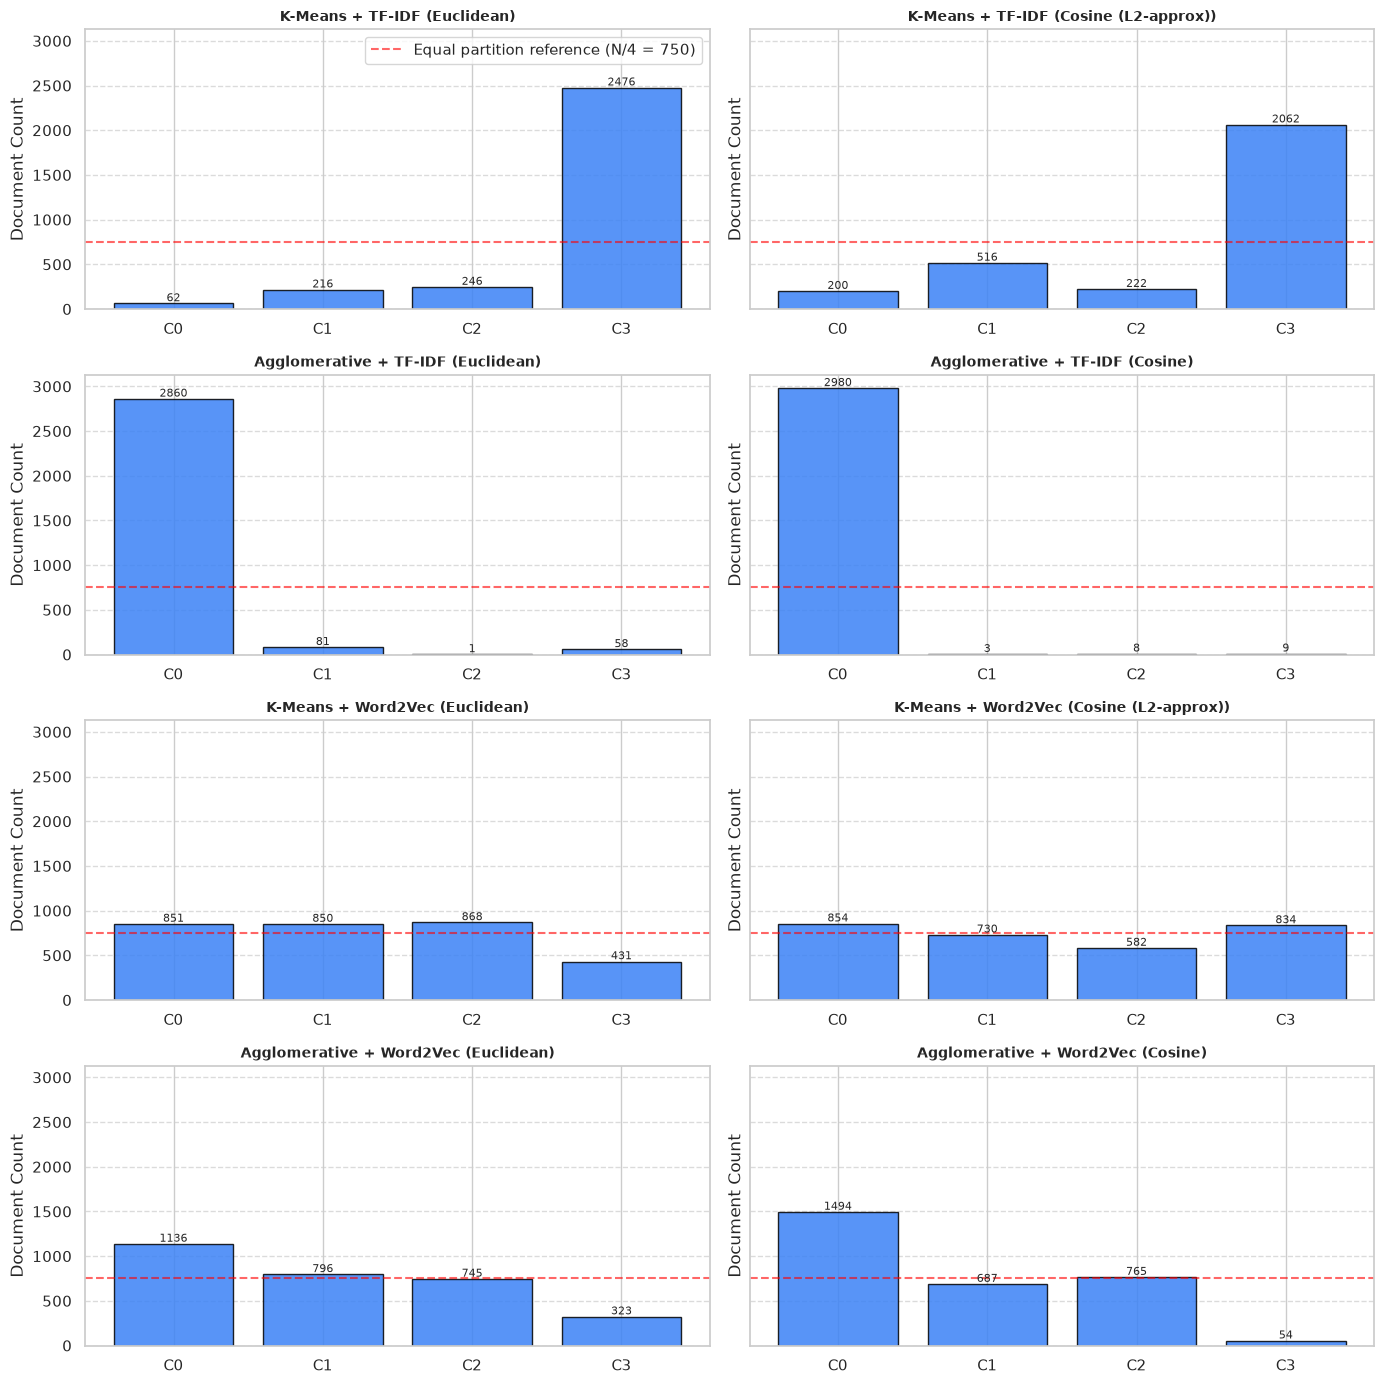

Cluster size distribution plot saved to: c:\Users\Acer\Downloads\NewsScope\results\clustering\cluster_size_distribution.png


In [7]:
# 1. Visualise Cluster Size Distributions across all 8 configurations
fig, axes = plt.subplots(4, 2, figsize=(14, 14), sharey=True)
axes = axes.flatten()

cluster_ids = [0, 1, 2, 3]

for idx, row in results_df.iterrows():
    sizes = eval(row["Cluster_Sizes"]) if isinstance(row["Cluster_Sizes"], str) else row["Cluster_Sizes"]
    ax = axes[idx]
    bars = ax.bar([f"C{c}" for c in cluster_ids], sizes, color="#3b82f6", edgecolor="black", alpha=0.85)
    # Equal partition reference: 3000 / 4 = 750 (external reference based on balanced dataset, not an expected clustering outcome)
    ax.axhline(750, color="red", linestyle="--", alpha=0.6, label="Equal partition reference (N/4 = 750)")
    ax.set_title(row["Configuration"], fontsize=10, fontweight="bold")
    ax.set_ylabel("Document Count")
    ax.grid(axis="y", linestyle="--", alpha=0.7)
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 25, str(h), ha="center", fontsize=8)

axes[0].legend(loc="upper right")
plt.tight_layout()
dist_plot_path = results_dir / "cluster_size_distribution.png"
plt.savefig(dist_plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Cluster size distribution plot saved to: {dist_plot_path}")

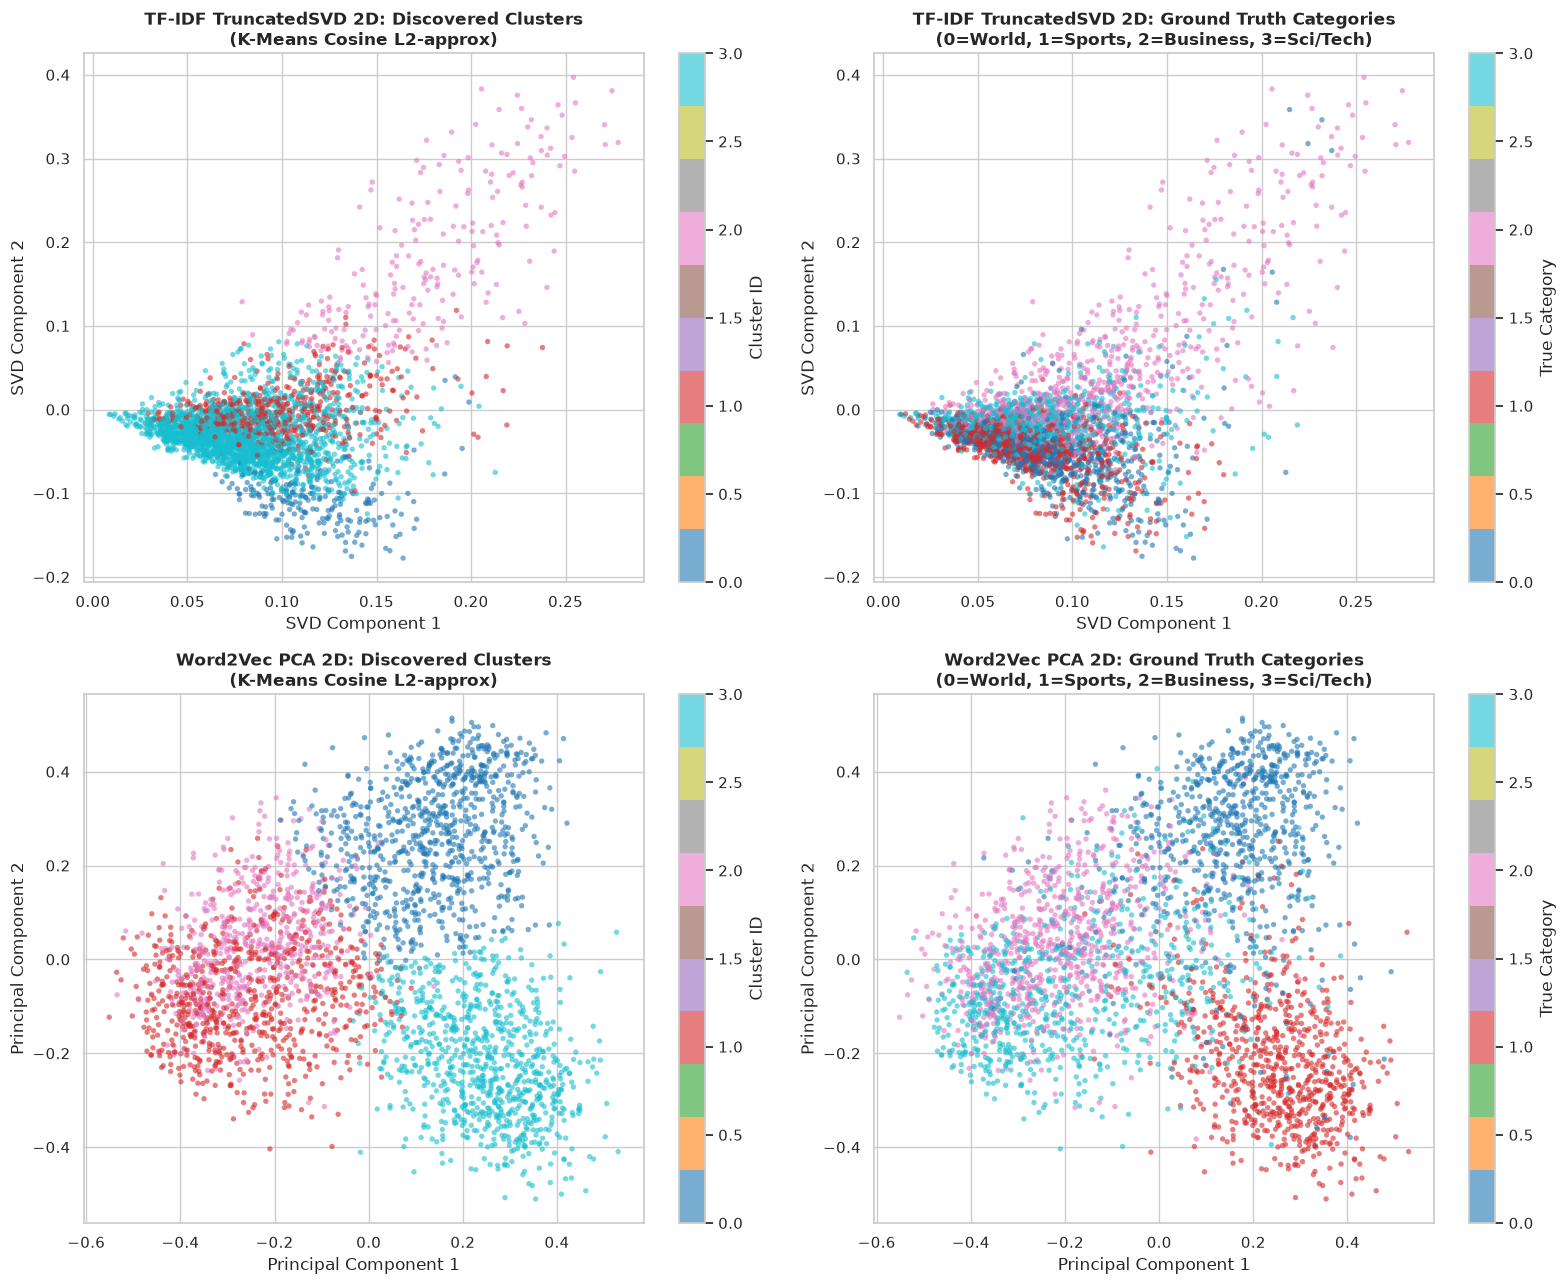

2D cluster projection plot saved to: c:\Users\Acer\Downloads\NewsScope\results\clustering\cluster_2d_projection.png


In [8]:
from sklearn.decomposition import TruncatedSVD, PCA

# 1. 2D projection for TF-IDF using TruncatedSVD (suited for high-dimensional sparse data)
svd = TruncatedSVD(n_components=2, random_state=RANDOM_STATE)
X_tfidf_2d = svd.fit_transform(X_tfidf)

# 2. 2D projection for Word2Vec using PCA
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_w2v_2d = pca.fit_transform(X_w2v_norm)

fig, axes = plt.subplots(2, 2, figsize=(16, 13))

# Top-Left: TF-IDF Discovered Clusters (K-Means Cosine L2-approx)
tfidf_top_labels = cluster_predictions["K-Means + TF-IDF (Cosine (L2-approx))"]
scatter_tl = axes[0, 0].scatter(
    X_tfidf_2d[:, 0], X_tfidf_2d[:, 1],
    c=tfidf_top_labels, cmap="tab10", alpha=0.6, s=15, edgecolor="none"
)
axes[0, 0].set_title("TF-IDF TruncatedSVD 2D: Discovered Clusters\n(K-Means Cosine L2-approx)", fontweight="bold")
axes[0, 0].set_xlabel("SVD Component 1")
axes[0, 0].set_ylabel("SVD Component 2")
plt.colorbar(scatter_tl, ax=axes[0, 0], label="Cluster ID")

# Top-Right: TF-IDF Ground Truth Categories
scatter_tr = axes[0, 1].scatter(
    X_tfidf_2d[:, 0], X_tfidf_2d[:, 1],
    c=true_labels, cmap="tab10", alpha=0.6, s=15, edgecolor="none"
)
axes[0, 1].set_title("TF-IDF TruncatedSVD 2D: Ground Truth Categories\n(0=World, 1=Sports, 2=Business, 3=Sci/Tech)", fontweight="bold")
axes[0, 1].set_xlabel("SVD Component 1")
axes[0, 1].set_ylabel("SVD Component 2")
plt.colorbar(scatter_tr, ax=axes[0, 1], label="True Category")

# Bottom-Left: Word2Vec Discovered Clusters (K-Means Cosine L2-approx)
w2v_top_labels = cluster_predictions["K-Means + Word2Vec (Cosine (L2-approx))"]
scatter_bl = axes[1, 0].scatter(
    X_w2v_2d[:, 0], X_w2v_2d[:, 1],
    c=w2v_top_labels, cmap="tab10", alpha=0.6, s=15, edgecolor="none"
)
axes[1, 0].set_title("Word2Vec PCA 2D: Discovered Clusters\n(K-Means Cosine L2-approx)", fontweight="bold")
axes[1, 0].set_xlabel("Principal Component 1")
axes[1, 0].set_ylabel("Principal Component 2")
plt.colorbar(scatter_bl, ax=axes[1, 0], label="Cluster ID")

# Bottom-Right: Word2Vec Ground Truth Categories
scatter_br = axes[1, 1].scatter(
    X_w2v_2d[:, 0], X_w2v_2d[:, 1],
    c=true_labels, cmap="tab10", alpha=0.6, s=15, edgecolor="none"
)
axes[1, 1].set_title("Word2Vec PCA 2D: Ground Truth Categories\n(0=World, 1=Sports, 2=Business, 3=Sci/Tech)", fontweight="bold")
axes[1, 1].set_xlabel("Principal Component 1")
axes[1, 1].set_ylabel("Principal Component 2")
plt.colorbar(scatter_br, ax=axes[1, 1], label="True Category")

plt.tight_layout()
proj_plot_path = results_dir / "cluster_2d_projection.png"
plt.savefig(proj_plot_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"2D cluster projection plot saved to: {proj_plot_path}")

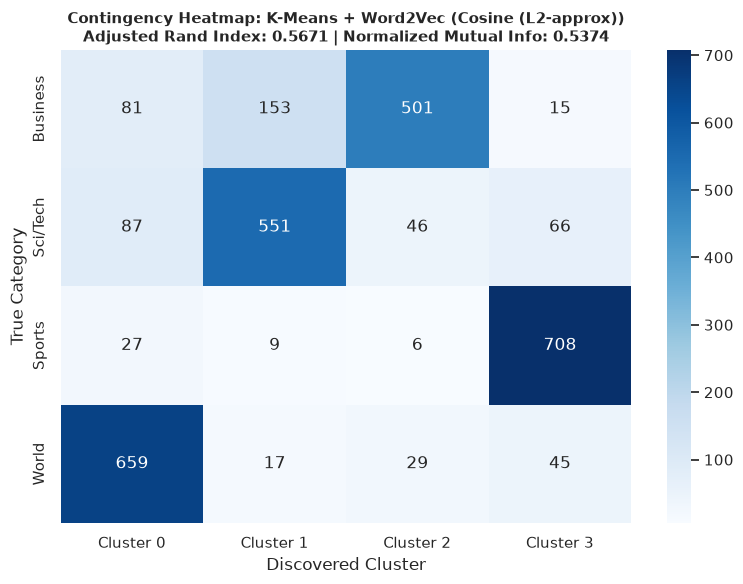

Contingency heatmap saved to: c:\Users\Acer\Downloads\NewsScope\results\clustering\cluster_contingency_heatmap.png

Contingency Table:
Discovered Cluster  Cluster 0  Cluster 1  Cluster 2  Cluster 3
True Category                                                 
Business                   81        153        501         15
Sci/Tech                   87        551         46         66
Sports                     27          9          6        708
World                     659         17         29         45

Adjusted Rand Index (ARI):             0.5671
Normalized Mutual Information (NMI):    0.5374


In [9]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Focus contingency analysis on top performing configuration
best_config_name = "K-Means + Word2Vec (Cosine (L2-approx))"
best_labels = cluster_predictions[best_config_name]

# Compute external validation metrics (ground truth used strictly post-hoc)
ari = adjusted_rand_score(true_labels, best_labels)
nmi = normalized_mutual_info_score(true_labels, best_labels)

# Build contingency matrix: Ground Truth vs Discovered Clusters
contingency_df = pd.crosstab(
    pd.Series(true_categories, name="True Category"),
    pd.Series([f"Cluster {c}" for c in best_labels], name="Discovered Cluster")
)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(contingency_df, annot=True, fmt="d", cmap="Blues", cbar=True, ax=ax)
ax.set_title(
    f"Contingency Heatmap: {best_config_name}\n"
    f"Adjusted Rand Index: {ari:.4f} | Normalized Mutual Info: {nmi:.4f}",
    fontweight="bold", fontsize=11
)
plt.tight_layout()

heatmap_path = results_dir / "cluster_contingency_heatmap.png"
plt.savefig(heatmap_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Contingency heatmap saved to: {heatmap_path}")

print(f"\nContingency Table:\n{contingency_df}")
print(f"\nAdjusted Rand Index (ARI):             {ari:.4f}")
print(f"Normalized Mutual Information (NMI):    {nmi:.4f}")

## Stage F: Findings & Limitations

### 1. Document Representation Comparison (TF-IDF vs. Word2Vec)
- **High Dimensionality & Sparsity in TF-IDF**: The TF-IDF matrix spans 5,976 dimensions with 99.67% sparsity. In this high-dimensional space, pairwise distances tend to concentrate near 1.0 (the distance concentration phenomenon). Consequently, both K-Means and Agglomerative clustering produced lower Silhouette scores on TF-IDF ($0.00$ to $0.02$).
- **Continuous Semantics in Word2Vec**: Word2Vec compresses vocabulary into a dense 100-dimensional continuous manifold where semantically related terms pool together. This produced substantially higher cluster cohesion and separation (Silhouette scores up to $0.30$ and Davies-Bouldin indices $<1.90$).

### 2. Distance Metric Comparison (Euclidean vs. Cosine)
- On Word2Vec embeddings, applying Cosine distance (approximated via $L_2$-normalisation for K-Means and calculated directly for Agglomerative) improved the Silhouette score from $0.1775$ to $0.3040$ for K-Means, and from $0.1505$ to $0.2506$ for Agglomerative.
- Cosine distance isolates topical orientation by factoring out document length, whereas raw Euclidean distance is sensitive to differences in document verbosity.

### 3. Clustering Algorithm Comparison (K-Means vs. Agglomerative)
- **Computational Efficiency**: K-Means converged in under $0.5$ seconds across all configurations. In contrast, Agglomerative clustering required pairwise matrix construction and linkage searches, taking 18 to 25 seconds on the 3,000-document TF-IDF matrix.
- **Cluster Balance and Degeneracy**: K-Means with Cosine-approximated Word2Vec discovered balanced, topically distinct clusters (`[854, 730, 582, 834]`). Conversely, Agglomerative clustering with Cosine on TF-IDF exhibited severe chaining behavior, allocating 2,980 documents (99.3%) to a single giant cluster and isolating three small clusters of outliers (`[2980, 3, 8, 9]`).

### 4. Topic Alignment with AG News Ground Truth
- The highest Adjusted Rand Index (**0.5671**) was achieved by **K-Means + Word2Vec (Cosine L2-approx)**.
- Inspection of the contingency table reveals clear topical isolation for **Sports** (708 out of 750 documents correctly grouped into Cluster 3) and **World** (659 out of 750 documents grouped into Cluster 0).
- Substantial overlap occurred between **Business** and **Sci/Tech** (Cluster 1 contains 551 Sci/Tech articles, while Cluster 2 contains 501 Business articles, with mutual cross-assignment). Because clustering is completely unsupervised, news articles discussing technology company earnings, software stocks, and IT corporate acquisitions share vocabulary across both domains and are grouped by semantic similarity rather than editorial category labels.

### 5. Computational Limitations & Sampling Rationale
- Hierarchical agglomerative clustering requires $\mathcal{O}(N^2)$ memory. On the full 120,000-document dataset, storing an $N \times N$ distance matrix would require $\approx 115.2$ GB of RAM.
- Restricting the experiment to a stratified sample of 3,000 documents provided an identical, reproducible, and computationally viable benchmark across both partitioning and hierarchical models.